# Прогнозирование конверсии в сервисе "СберАвтоподписка" # 

In [114]:
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
import joblib
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_curve
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer


##  Ознакомление с описаниями представленных атрибутов ##

In [2]:
# Загружаем данные
sessions = pd.read_pickle('ga_sessions.pkl')
print(f'Размер: {sessions.shape}')
print(f'Колонки: {sessions.columns.tolist()}')   

Размер: (1860042, 18)
Колонки: ['session_id', 'client_id', 'visit_date', 'visit_time', 'visit_number', 'utm_source', 'utm_medium', 'utm_campaign', 'utm_adcontent', 'utm_keyword', 'device_category', 'device_os', 'device_brand', 'device_model', 'device_screen_resolution', 'device_browser', 'geo_country', 'geo_city']


In [3]:
hits = pd.read_pickle('ga_hits.pkl')
print(f'Размер: {hits.shape}')
print(f'Колонки: {hits.columns.tolist()}') 

Размер: (15726470, 11)
Колонки: ['session_id', 'hit_date', 'hit_time', 'hit_number', 'hit_type', 'hit_referer', 'hit_page_path', 'event_category', 'event_action', 'event_label', 'event_value']


In [4]:
sessions.head() 

,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,NaN,360x720,Chrome,Russia,Zlatoust
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,mobile,Android,Samsung,NaN,385x854,Samsung Internet,Russia,Moscow
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,NaN,360x720,Chrome,Russia,Krasnoyarsk
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,NaN,NOBKLgtuvqYWkXQHeYWM,NaN,mobile,None,Xiaomi,NaN,393x786,Chrome,Russia,Moscow
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,NaN,NaN,NaN,mobile,None,Xiaomi,NaN,393x786,Chrome,Russia,Moscow


In [9]:
hits.head()   

,session_id,hit_date,hit_time,hit_number,hit_type,hit_referer,hit_page_path,event_category,event_action,event_label,event_value
0,5639623078712724064.1640254056.1640254056,2021-12-23,597864.0,30,event,NaN,sberauto.com/cars?utm_source_initial=google&ut...,quiz,quiz_show,NaN,None
1,7750352294969115059.1640271109.1640271109,2021-12-23,597331.0,41,event,NaN,sberauto.com/cars/fiat?city=1&city=18&rental_c...,quiz,quiz_show,NaN,None
2,885342191847998240.1640235807.1640235807,2021-12-23,796252.0,49,event,NaN,sberauto.com/cars/all/volkswagen/polo/e994838f...,quiz,quiz_show,NaN,None
3,142526202120934167.1640211014.1640211014,2021-12-23,934292.0,46,event,NaN,sberauto.com/cars?utm_source_initial=yandex&ut...,quiz,quiz_show,NaN,None
4,3450086108837475701.1640265078.1640265078,2021-12-23,768741.0,79,event,NaN,sberauto.com/cars/all/mercedes-benz/cla-klasse...,quiz,quiz_show,NaN,None


In [4]:
print("Информация о sessions:")
print(sessions.info())
print("Статистика по числовым колонкам sessions:")
print(sessions.describe())

print("Информация о hits:")
print(hits.info())
print("Статистика по числовым колонкам hits:")
print(hits.describe())   

Информация о sessions:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1860042 entries, 0 to 1860041
Data columns (total 18 columns):
 #   Column                    Dtype 
---  ------                    ----- 
 0   session_id                object
 1   client_id                 object
 2   visit_date                object
 3   visit_time                object
 4   visit_number              int64 
 5   utm_source                object
 6   utm_medium                object
 7   utm_campaign              object
 8   utm_adcontent             object
 9   utm_keyword               object
 10  device_category           object
 11  device_os                 object
 12  device_brand              object
 13  device_model              object
 14  device_screen_resolution  object
 15  device_browser            object
 16  geo_country               object
 17  geo_city                  object
dtypes: int64(1), object(17)
memory usage: 255.4+ MB
None
Статистика по числовым колонкам sessions:
    

*Ключ связи: session_id, этот идентификатор есть в обеих таблицах и уникально определяет один визит на сайт. Тип связи: один ко многим.*

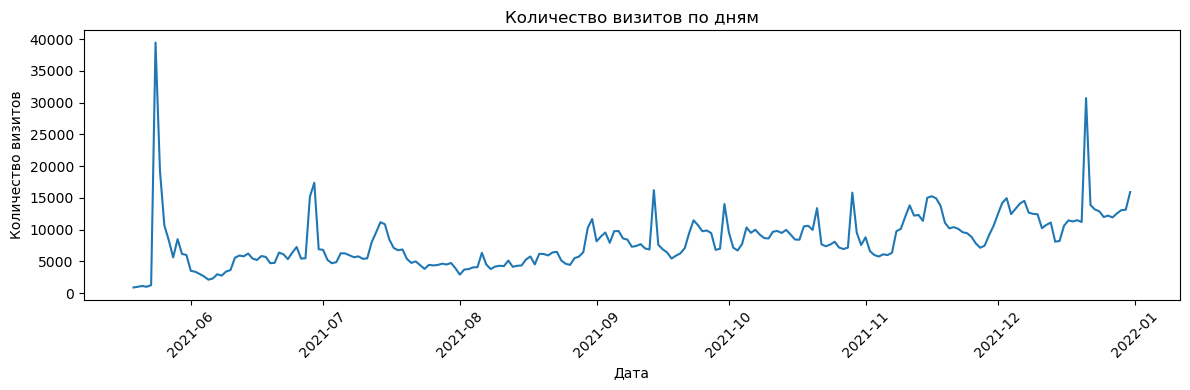

In [5]:
# Динамика визитов по дням
plt.figure(figsize=(12, 4))
sessions['visit_date'] = pd.to_datetime(sessions['visit_date'])
daily_visits = sessions.groupby('visit_date').size()
plt.plot(daily_visits.index, daily_visits.values)
plt.title('Количество визитов по дням')
plt.xlabel('Дата')
plt.ylabel('Количество визитов')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show() 

Text(0.5, 1.0, 'Типы устройств')

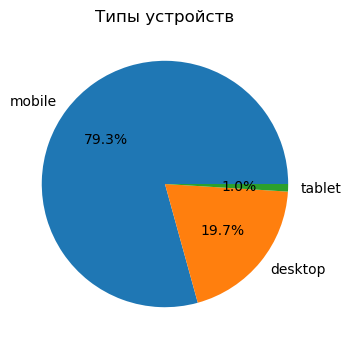

In [6]:
#  Распределение типов устройств 
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
device_counts = sessions['device_category'].value_counts()
plt.pie(device_counts, labels=device_counts.index, autopct='%1.1f%%')
plt.title('Типы устройств')

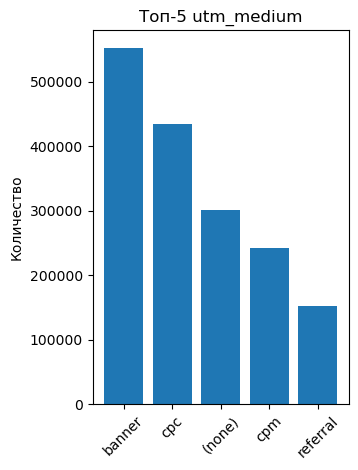

Типы трафика (utm_medium):
utm_medium
banner      552272
cpc         434794
(none)      300575
cpm         242083
referral    152050
organic      63034
email        29240
push         28035
stories      10582
cpv           8022
Name: count, dtype: int64


In [7]:
# топ utm_medium 
plt.subplot(1, 2, 2)
medium_top = sessions['utm_medium'].value_counts().head(5)
plt.bar(medium_top.index, medium_top.values)
plt.title('Топ-5 utm_medium')
plt.ylabel('Количество')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Типы трафика (utm_medium):")
print(sessions['utm_medium'].value_counts().head(10)) 

## Анализ выбросов и распределения данных ##

In [8]:
# visit_number
Q1 = sessions['visit_number'].quantile(0.25)
Q3 = sessions['visit_number'].quantile(0.75)
IQR = Q3 - Q1
upper = Q3 + 1.5 * IQR
outliers_visit = sessions[sessions['visit_number'] > upper]
print(f'visit_number: {len(outliers_visit)} выбросов, верхняя граница: {upper:.0f}, максимум: {sessions['visit_number'].max()}')

# hit_number
Q1 = hits['hit_number'].quantile(0.25)
Q3 = hits['hit_number'].quantile(0.75)
IQR = Q3 - Q1
upper = Q3 + 1.5 * IQR
outliers_hit = hits[hits['hit_number'] > upper]
print(f'hit_number: {len(outliers_hit)} выбросов, верхняя граница: {upper:.0f}, максимум: {hits['hit_number'].max()}')

# hit_time
hit_time_clean = hits['hit_time'].dropna()
if len(hit_time_clean) > 0:
    Q1, Q3 = hit_time_clean.quantile(0.25), hit_time_clean.quantile(0.75)
    upper = Q3 + 1.5 * (Q3 - Q1)
    outliers_time = hit_time_clean[hit_time_clean > upper]
    print(f'hit_time: {len(outliers_time)} выбросов, верхняя граница: {upper:.0f}, максимум: {hit_time_clean.max():.0f}') 
    

visit_number: 166969 выбросов, верхняя граница: 4, максимум: 564
hit_number: 1061598 выбросов, верхняя граница: 62, максимум: 500
hit_time: 621834 выбросов, верхняя граница: 512658, максимум: 13156885


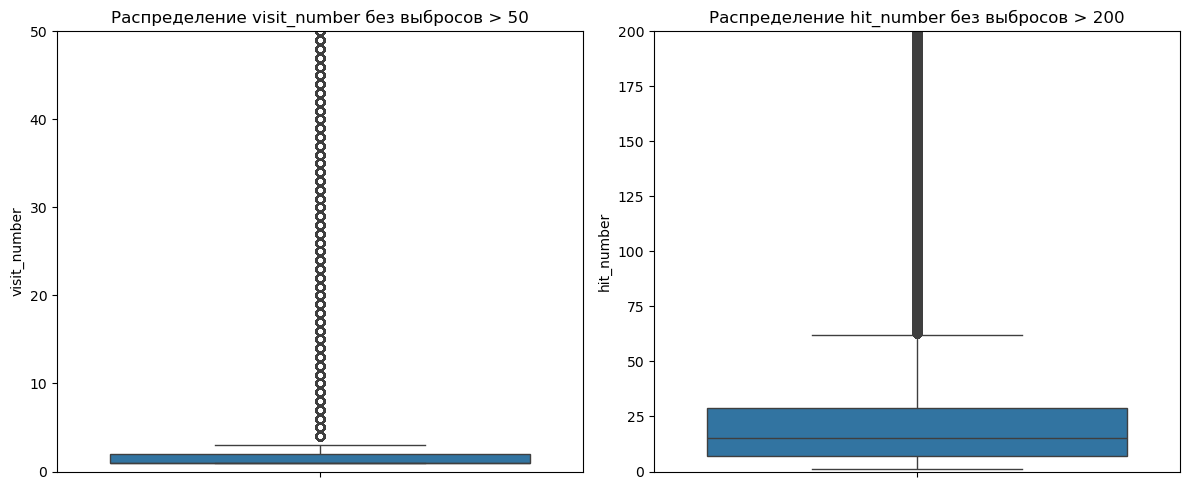

In [113]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# visit_number
sns.boxplot(y=sessions['visit_number'], ax=axes[0])
axes[0].set_ylim(0, 50)  
axes[0].set_title('Распределение visit_number без выбросов > 50')

# hit_number 
sns.boxplot(y=hits['hit_number'], ax=axes[1])
axes[1].set_ylim(0, 200) 
axes[1].set_title('Распределение hit_number без выбросов > 200')

plt.tight_layout()
plt.show() 

In [111]:
print("Распределение данных:")
values = [50, 75, 90, 95, 99, 99.5, 99.9, 100]
data = {
    'Доля данных': [f'{v}%' for v in values],
    'visit_number': [sessions['visit_number'].quantile(v/100) for v in values],
    'hit_number': [hits['hit_number'].quantile(v/100) for v in values],
}

# hit_time
hit_time_clean = hits['hit_time'].dropna()
data['hit_time (сек)'] = [hit_time_clean.quantile(v/100) for v in values]
df_stats = pd.DataFrame(data)
df_stats['visit_number'] = df_stats['visit_number'].astype(int)
df_stats['hit_number'] = df_stats['hit_number'].astype(int)
df_stats['hit_time (сек)'] = df_stats['hit_time (сек)'].astype(int)

print(df_stats.to_string(index=False))    

Распределение данных:
Доля данных  visit_number  hit_number  hit_time (сек)
        50%             1          15           89941
        75%             2          29          219535
        90%             3          51          490205
        95%             6          72          821274
        99%            32         137         1963729
      99.5%            67         176         2530693
      99.9%           189         308         4295955
       100%           564         500        13156885


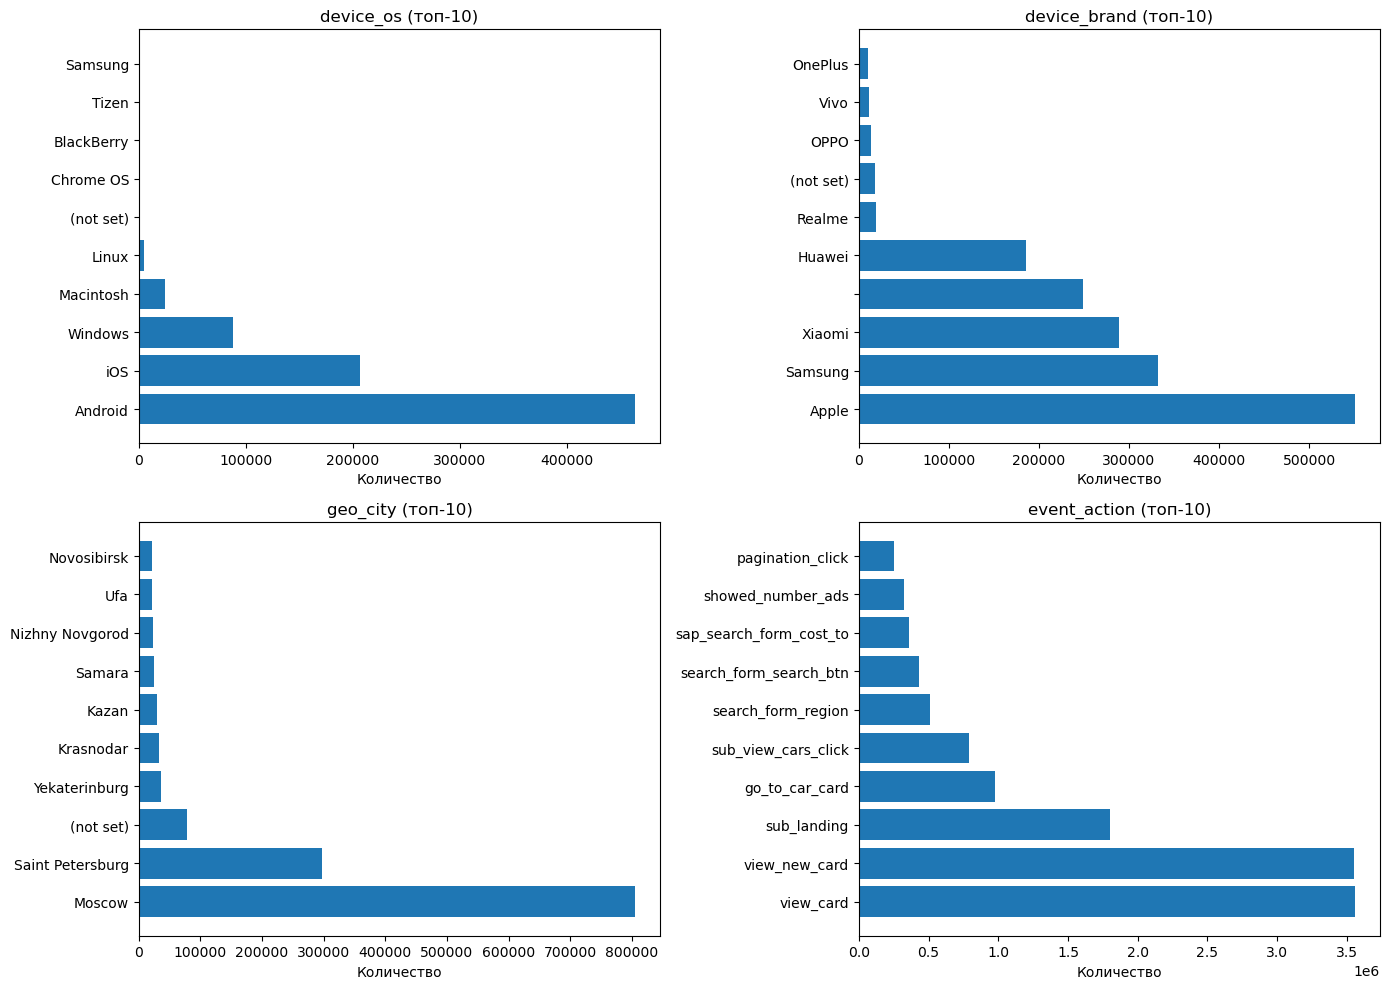

In [10]:
# анализ категорииальных признаков

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
#  device_os 
os_top = sessions['device_os'].value_counts().head(10)
axes[0, 0].barh(os_top.index, os_top.values)
axes[0, 0].set_title('device_os (топ-10)')
axes[0, 0].set_xlabel('Количество')

# device_brand 
brand_top = sessions['device_brand'].value_counts().head(10)
axes[0, 1].barh(brand_top.index, brand_top.values)
axes[0, 1].set_title('device_brand (топ-10)')
axes[0, 1].set_xlabel('Количество')

# geo_city 
city_top = sessions['geo_city'].value_counts().head(10)
axes[1, 0].barh(city_top.index, city_top.values)
axes[1, 0].set_title('geo_city (топ-10)')
axes[1, 0].set_xlabel('Количество')

# event_action 
action_top = hits['event_action'].value_counts().head(10)
axes[1, 1].barh(action_top.index, action_top.values)
axes[1, 1].set_title('event_action (топ-10)')
axes[1, 1].set_xlabel('Количество')

plt.tight_layout()
plt.show() 

## Data Cleaning ##

### Работа с пропусками и дубликатами ###

In [11]:
#анализ пропусков 
missing_sessions = sessions.isnull().sum()
missing_percent_sessions = (missing_sessions / len(sessions)) * 100
missing_df_sessions = pd.DataFrame({'Количество пропусков': missing_sessions, 'Процент пропусков': missing_percent_sessions})
print("Пропуски в sessions:")
print(missing_df_sessions[missing_df_sessions['Количество пропусков'] > 0].sort_values('Процент пропусков', ascending=False))   

Пропуски в sessions:
               Количество пропусков  Процент пропусков
device_model                1843704          99.121633
utm_keyword                 1082061          58.174009
device_os                   1070138          57.533002
utm_adcontent                335615          18.043410
utm_campaign                 219603          11.806346
device_brand                 118678           6.380394
utm_source                       97           0.005215


In [12]:
missing_hits = hits.isnull().sum()
missing_percent_hits = (missing_hits / len(hits)) * 100
missing_df_hits = pd.DataFrame({'Количество пропусков': missing_hits, 'Процент пропусков': missing_percent_hits})
print("Пропуски в hits:")
print(missing_df_hits[missing_df_hits['Количество пропусков'] > 0].sort_values('Процент пропусков', ascending=False)) 

Пропуски в hits:
             Количество пропусков  Процент пропусков
event_value              15726470         100.000000
hit_time                  9160322          58.247795
hit_referer               6274804          39.899634
event_label               3760184          23.909905


In [ ]:
# копии датасетов
sessions_clean = sessions.copy()
hits_clean = hits.copy() 

In [31]:
# Удаляем колонки, где больше 55% пропусков:
cols_drop_sessions = ['device_model', 'utm_keyword', 'device_os']
cols_drop_hits = ['event_value', 'hit_time']

sessions_clean = sessions_clean.drop(columns=cols_drop_sessions)
hits_clean = hits_clean.drop(columns=cols_drop_hits)   

In [36]:
# удаляем полные дубликаты строк
print(f'До удаления дубликатов sessions: {len(sessions_clean)}')
sessions_clean = sessions_clean.drop_duplicates()
print(f'После: {len(sessions_clean)}')

print(f'До удаления дубликатов hits: {len(hits_clean)}')
hits_clean = hits_clean.drop_duplicates()
print(f'После: {len(hits_clean)}')   

До удаления дубликатов sessions: 1860042
После: 1860042
До удаления дубликатов hits: 15500608
После: 15500608


In [33]:
# Проверяем дубликаты по ключу 
duplicates_key = hits_clean.duplicated(subset=['session_id', 'hit_number']).sum()
print(f'Дубликатов по (session_id, hit_number): {duplicates_key}')

Дубликатов по (session_id, hit_number): 223537


In [37]:
# Удаляем дубликаты по ключу - оставим только первое событие
hits_clean = hits_clean.drop_duplicates(subset=['session_id', 'hit_number'], keep='first')

duplicates_key_after = hits_clean.duplicated(subset=['session_id', 'hit_number']).sum()
print(f'Дубликатов после удаления: {duplicates_key_after}')
print(f'Размер hits_clean: {hits_clean.shape}')  

Дубликатов после удаления: 0
Размер hits_clean: (15500608, 9)


In [38]:
# Заполняем пропуски в оставшихся колонках
# Sessions
sessions_clean['utm_adcontent'] = sessions_clean['utm_adcontent'].fillna('unknown')
sessions_clean['utm_campaign'] = sessions_clean['utm_campaign'].fillna('unknown')
sessions_clean['device_brand'] = sessions_clean['device_brand'].fillna('unknown')
sessions_clean['utm_source'] = sessions_clean['utm_source'].fillna('unknown')

In [41]:
hits_clean.columns.tolist()  

['session_id',
 'hit_date',
 'hit_number',
 'hit_type',
 'hit_referer',
 'hit_page_path',
 'event_category',
 'event_action',
 'event_label']

 ***Для работы из hits_clean нужны только session_id - для связки, event_action - для определения целевого действия.***
**Остальные колонки удаляю:**
* **hit_date, дата события, есть visit_date в sessions**
* **hit_number, hit_referer,hit_page_path, hit_type, hit_page_path - действия пользователя на сайте, но мы будем предсказывать до того, как он зашёл на сайт**
* **event_label - тег события, много пропусков, не нужно для target**
* **event_category - категория избыточна, так как мы и так используем event_action**

In [42]:
cols_to_drop = [
    'hit_date', 
    'hit_number', 
    'hit_type', 
    'hit_referer', 
    'hit_page_path', 
    'event_category', 
    'event_label'
]
hits_clean = hits_clean.drop(columns=cols_to_drop)
print(f'Колонки после удаления: {hits_clean.columns.tolist()}')
print(f'Размер hits_clean: {hits_clean.shape}') 

Колонки после удаления: ['session_id', 'event_action']
Размер hits_clean: (15500608, 2)


### Преобразование типов данных ###

In [43]:
# Преобразование дат
sessions_clean['visit_date'] = pd.to_datetime(sessions_clean['visit_date'])

In [44]:
# Преобразуем время в секунды 
# Преобразуем всё в строки
sessions_clean['visit_time'] = sessions_clean['visit_time'].astype(str)
# Теперь split работает
sessions_clean['visit_seconds'] = sessions_clean['visit_time'].str.split(':').apply(
    lambda x: int(x[0])*3600 + int(x[1])*60 + int(x[2])
) 

sessions_clean = sessions_clean.drop(columns=['visit_time']) #удаляю visit_time 

In [45]:
# Преобразование категориальных признаков
cat_cols_sessions = ['utm_source', 'utm_medium', 'utm_campaign', 'utm_adcontent', 
                      'device_category', 'device_os', 'device_brand', 
                      'device_browser', 'geo_country', 'geo_city']

cat_cols_hits = ['event_action']

for col in cat_cols_sessions:
    if col in sessions_clean.columns:
        sessions_clean[col] = sessions_clean[col].astype('category')

for col in cat_cols_hits:
    if col in hits_clean.columns:
        hits_clean[col] = hits_clean[col].astype('category') 

In [46]:
# разрешение экрана
sessions_clean[['screen_width', 'screen_height']] = sessions_clean['device_screen_resolution'].str.extract(r'(\d+)x(\d+)').astype(float)
sessions_clean = sessions_clean.drop(columns=['device_screen_resolution'])

In [47]:
# Проверяем
print("Типы в sessions_clean:")
print(sessions_clean.dtypes)
print("Типы в hits_clean:")
print(hits_clean.dtypes) 

Типы в sessions_clean:
session_id                 object
client_id                  object
visit_date         datetime64[ns]
visit_number                int64
utm_source               category
utm_medium               category
utm_campaign             category
utm_adcontent            category
device_category          category
device_brand             category
device_browser           category
geo_country              category
geo_city                 category
visit_seconds               int64
screen_width              float64
screen_height             float64
dtype: object
Типы в hits_clean:
session_id        object
event_action    category
dtype: object


## Создание целевой переменной ##

In [48]:
# Целевые действия 
target_events = [
    'sub_car_claim_click', 'sub_car_claim_submit_click', 'sub_open_dialog_click',
    'sub_custom_question_submit_click', 'sub_call_number_click', 'sub_callback_submit_click',
    'sub_submit_success', 'sub_car_request_submit_click'
] 

In [49]:
# оставляем строки с целевыми событиями
target_hits = hits_clean[hits_clean['event_action'].isin(target_events)]
# берём уникальные session_id
sessions_with_target = target_hits['session_id'].unique()

print(f'Сессий с целевыми действиями: {len(sessions_with_target)}')
print(f'Всего сессий: {len(sessions_clean)}')

Сессий с целевыми действиями: 50760
Всего сессий: 1860042


In [50]:
# Создаём датафрейм с целевой переменной, берём все уникальные session_id из sessions_clean
target_df = pd.DataFrame({'session_id': sessions_clean['session_id'].unique()}) 

In [51]:
# преобразуем в 1/0: 1 если конверсия есть, 0 если нет
target_df['target'] = target_df['session_id'].isin(sessions_with_target).astype(int)

In [52]:
print("Распредделение целевой переменной:")
print(target_df['target'].value_counts())
print(f'Доля сессий с целевым действием: {target_df['target'].mean()*100:.2f}%')
# Проверяем, что нет пропусков
print(f'Пропуски в target: {target_df['target'].isnull().sum()}')

Распредделение целевой переменной:
target
0    1809728
1      50314
Name: count, dtype: int64
Доля сессий с целевым действием: 2.70%
Пропуски в target: 0


*У нас сильный дисбаланс классов. Нужно будет использовать class_weight='balanced'*

In [53]:
# потерянные сессии
lost_sessions = set(sessions_with_target) - set(sessions_clean['session_id'].unique())
print(f"Потерянных сессий: {len(lost_sessions)}")

Потерянных сессий: 446


*Эти 446 сессий есть в hits, но нет в sessions.
При создании целевой переменной мы используем только session_id из sessions_clean,
поэтому эти сессии просто не попадают в target_df.*

## Feature Engineering ## 

In [70]:
sessions_work = sessions_clean.copy() 

In [71]:
# Из sessions_work удаляем client_id, он не нужен для работы
sessions_work = sessions_work.drop(columns=['client_id'])
print(f'sessions_work колонки: {sessions_work.columns.tolist()}') 

sessions_work колонки: ['session_id', 'visit_date', 'visit_number', 'utm_source', 'utm_medium', 'utm_campaign', 'utm_adcontent', 'device_category', 'device_brand', 'device_browser', 'geo_country', 'geo_city', 'visit_seconds', 'screen_width', 'screen_height']


In [72]:
# Создаём новые признаки времени
sessions_work['visit_hour'] = sessions_work['visit_seconds'] // 3600
sessions_work['is_weekend'] = (sessions_work['visit_date'].dt.dayofweek >= 5).astype(int) 

In [73]:
# Признаки только из sessions
model_df = sessions_work.copy()
# Добавляем целевую переменную
model_df = model_df.merge(target_df, on='session_id', how='left')

print(f'Размер model_df: {model_df.shape}')
print(model_df.columns.tolist()) 

Размер model_df: (1860042, 18)
['session_id', 'visit_date', 'visit_number', 'utm_source', 'utm_medium', 'utm_campaign', 'utm_adcontent', 'device_category', 'device_brand', 'device_browser', 'geo_country', 'geo_city', 'visit_seconds', 'screen_width', 'screen_height', 'visit_hour', 'is_weekend', 'target']


In [74]:
print(model_df.isnull().sum().sum())

16


In [75]:
print(model_df.isnull().sum()[model_df.isnull().sum() > 0]) 

screen_width     8
screen_height    8
dtype: int64


In [76]:
model_df['screen_width'] = model_df['screen_width'].fillna(0)
model_df['screen_height'] = model_df['screen_height'].fillna(0)

print(f'Пропуски после исправления: {model_df.isnull().sum().sum()}')

Пропуски после исправления: 0


In [77]:
# Удаляем колонки, которые больше не нужны
model_df = model_df.drop(columns=['session_id', 'visit_date', 'visit_seconds'])

print(f'Колонки после удаления: {model_df.columns.tolist()}')
print(f'Размер: {model_df.shape}') 

Колонки после удаления: ['visit_number', 'utm_source', 'utm_medium', 'utm_campaign', 'utm_adcontent', 'device_category', 'device_brand', 'device_browser', 'geo_country', 'geo_city', 'screen_width', 'screen_height', 'visit_hour', 'is_weekend', 'target']
Размер: (1860042, 15)


##  Подготовка к моделированию ##


In [78]:
# разделяем на признаки и целевую переменную
X = model_df.drop(columns=['target'])
y = model_df['target']

print(f'X shape: {X.shape}')
print(f'y shape: {y.shape}') 

X shape: (1860042, 14)
y shape: (1860042,)


In [80]:
categorical_cols = X.select_dtypes(include=['category']).columns.tolist()
numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

print(f'Категориальные ({len(categorical_cols)}): {categorical_cols}')
print(f'Числовые ({len(numeric_cols)}): {numeric_cols}') 

Категориальные (9): ['utm_source', 'utm_medium', 'utm_campaign', 'utm_adcontent', 'device_category', 'device_brand', 'device_browser', 'geo_country', 'geo_city']
Числовые (5): ['visit_number', 'screen_width', 'screen_height', 'visit_hour', 'is_weekend']


In [81]:
categorical_cols_check = X.select_dtypes(include=['category']).columns.tolist()

print("Уникальные значения в категориальных признаках:")
for col in categorical_cols_check:
    print(f'{col}: {X[col].nunique()} уникальных значений') 

Уникальные значения в категориальных признаках:
utm_source: 294 уникальных значений
utm_medium: 56 уникальных значений
utm_campaign: 413 уникальных значений
utm_adcontent: 287 уникальных значений
device_category: 3 уникальных значений
device_brand: 207 уникальных значений
device_browser: 57 уникальных значений
geo_country: 166 уникальных значений
geo_city: 2548 уникальных значений


In [82]:
# гуппировка редких категорий , чтобы  не было переобучения
# geo_city
top_cities = X['geo_city'].value_counts().head(100).index
X['geo_city'] = X['geo_city'].apply(lambda x: x if x in top_cities else 'other')
print(f"geo_city: {X['geo_city'].nunique()} уникальных")

# utm_campaign
top_campaigns = X['utm_campaign'].value_counts().head(100).index
X['utm_campaign'] = X['utm_campaign'].apply(lambda x: x if x in top_campaigns else 'other')
print(f"utm_campaign: {X['utm_campaign'].nunique()} уникальных")

# utm_source
top_sources = X['utm_source'].value_counts().head(100).index
X['utm_source'] = X['utm_source'].apply(lambda x: x if x in top_sources else 'other')
print(f"utm_source: {X['utm_source'].nunique()} уникальных")

# utm_adcontent
top_adcontent = X['utm_adcontent'].value_counts().head(100).index
X['utm_adcontent'] = X['utm_adcontent'].apply(lambda x: x if x in top_adcontent else 'other')
print(f"utm_adcontent: {X['utm_adcontent'].nunique()} уникальных") 

geo_city: 101 уникальных
utm_campaign: 101 уникальных
utm_source: 101 уникальных
utm_adcontent: 101 уникальных


In [83]:
# кодирование категорий
enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_encoded = X.copy()
X_encoded[categorical_cols] = enc.fit_transform(X[categorical_cols]) 

In [84]:
print(f'Новые типы: {X_encoded[categorical_cols].dtypes.value_counts()}')

Новые типы: float64    9
Name: count, dtype: int64


In [86]:
print(f'Пропуски в X_encoded: {X_encoded.isnull().sum().sum()}') 

Пропуски в X_encoded: 0


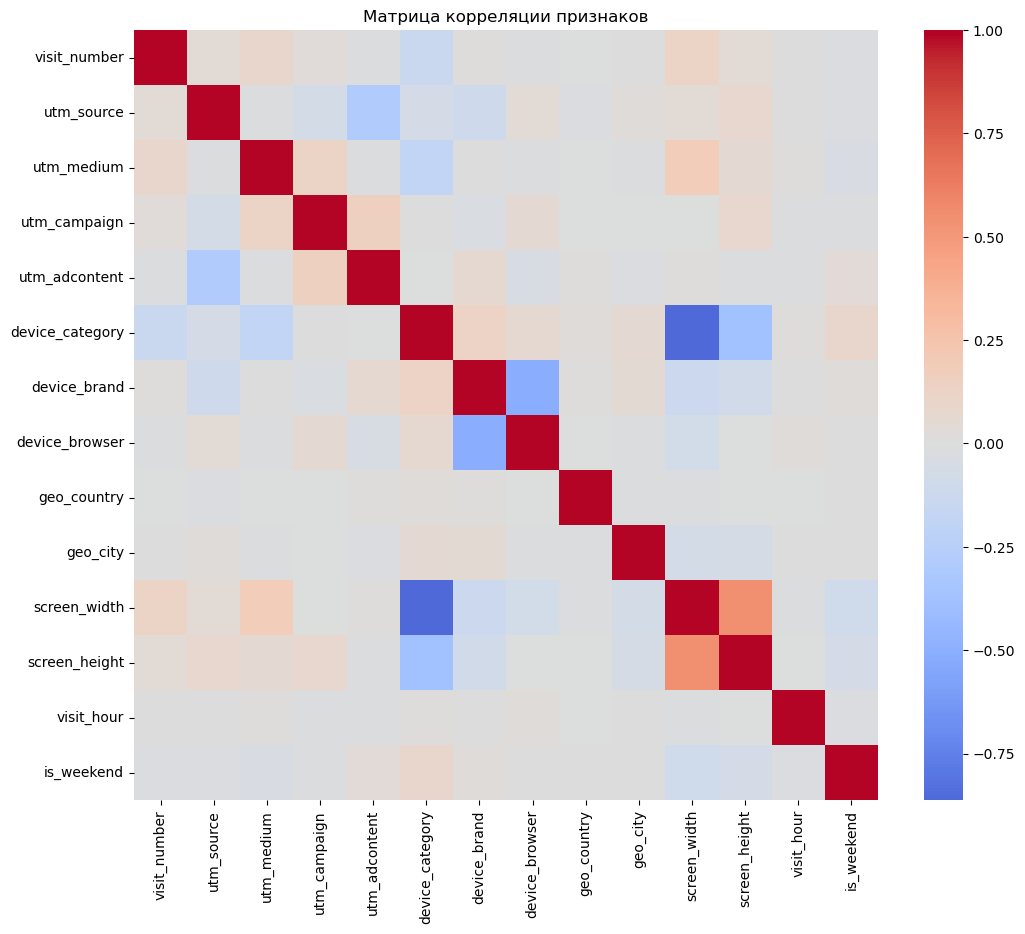

In [87]:
corr_matrix = X_encoded.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', center=0)
plt.title('Матрица корреляции признаков')
plt.show()

In [88]:
print("До масштабирования:")
print(X_encoded[numeric_cols].describe()) 

До масштабирования:
       visit_number  screen_width  screen_height    visit_hour    is_weekend
count  1.860042e+06  1.860042e+06   1.860042e+06  1.860042e+06  1.860042e+06
mean   2.712804e+00  6.567031e+02   8.408702e+02  1.361912e+01  2.430639e-01
std    1.182907e+01  5.531455e+02   1.939711e+02  6.121915e+00  4.289335e-01
min    1.000000e+00  0.000000e+00   0.000000e+00  0.000000e+00  0.000000e+00
25%    1.000000e+00  3.600000e+02   7.600000e+02  1.000000e+01  0.000000e+00
50%    1.000000e+00  3.930000e+02   8.440000e+02  1.400000e+01  0.000000e+00
75%    2.000000e+00  4.280000e+02   8.960000e+02  1.900000e+01  0.000000e+00
max    5.640000e+02  5.924000e+03   2.000000e+04  2.300000e+01  1.000000e+00


In [89]:
# Масштабирование числовых признаков
scaler = RobustScaler()
X_encoded[numeric_cols] = scaler.fit_transform(X_encoded[numeric_cols])

print("После масштабирования:")
print(X_encoded[numeric_cols].describe())   

После масштабирования:
       visit_number  screen_width  screen_height    visit_hour    is_weekend
count  1.860042e+06  1.860042e+06   1.860042e+06  1.860042e+06  1.860042e+06
mean   1.712804e+00  3.877987e+00  -2.301324e-02 -4.231983e-02  2.430639e-01
std    1.182907e+01  8.134493e+00   1.426258e+00  6.802128e-01  4.289335e-01
min    0.000000e+00 -5.779412e+00  -6.205882e+00 -1.555556e+00  0.000000e+00
25%    0.000000e+00 -4.852941e-01  -6.176471e-01 -4.444444e-01  0.000000e+00
50%    0.000000e+00  0.000000e+00   0.000000e+00  0.000000e+00  0.000000e+00
75%    1.000000e+00  5.147059e-01   3.823529e-01  5.555556e-01  0.000000e+00
max    5.630000e+02  8.133824e+01   1.408529e+02  1.000000e+00  1.000000e+00


In [90]:
# финальный датасет для моделирования
model_ready = X_encoded.copy()
model_ready['target'] = y

print(f'Размер model_ready: {model_ready.shape}')
print(f'Колонки: {model_ready.columns.tolist()}') 

Размер model_ready: (1860042, 15)
Колонки: ['visit_number', 'utm_source', 'utm_medium', 'utm_campaign', 'utm_adcontent', 'device_category', 'device_brand', 'device_browser', 'geo_country', 'geo_city', 'screen_width', 'screen_height', 'visit_hour', 'is_weekend', 'target']


In [91]:
print(model_ready.dtypes.value_counts())

float64    14
int64       1
Name: count, dtype: int64


## Обучение модели ##

***Буду использовать модель Random Forest. В выборке целевых действий меньше 3%, модель будет обращать внимание на редкие конверсии. У нас 9 категориальных признаков, они были закодированы через OrdinalEncoder, с которым случайный лес хорошо работает, соответственно отпадает нужда в создании отдельной колонки для каждой категории(их было бы очень много). В отличие от линейной модели, случайный лес должен нормально отработать с выбросами, которые у нас есть. Также, Random Forest покажет, какие признаки сильнее всего влияют на конверсию.***

In [93]:
X = model_ready.drop(columns=['target'])
y = model_ready['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
) 

In [94]:
# Baseline 
print("Baseline:")
dummy = DummyClassifier(strategy='stratified', random_state=42)
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict_proba(X_test)[:, 1]
dummy_auc = roc_auc_score(y_test, y_pred_dummy)
print(f'DummyClassifier ROC-AUC: {dummy_auc:.4f}') 

Baseline:
DummyClassifier ROC-AUC: 0.4993


In [96]:
# подбор параметров для случайного леса
param_grid = {
    'n_estimators': [100, 150],
    'max_depth': [10, 12],
    'min_samples_split': [50, 100],
    'min_samples_leaf': [25, 50],
}

rf = RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=8)

grid_search = GridSearchCV(
    rf,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=2,            
    verbose=2,
    n_jobs=4           
)

grid_search.fit(X_train, y_train)

print(f'Лучшие параметры: {grid_search.best_params_}')
print(f'Лучший ROC-AUC: {grid_search.best_score_:.4f}') 

Fitting 2 folds for each of 16 candidates, totalling 32 fits
Лучшие параметры: {'max_depth': 12, 'min_samples_leaf': 50, 'min_samples_split': 50, 'n_estimators': 100}
Лучший ROC-AUC: 0.6919


In [97]:
best_model = RandomForestClassifier(**grid_search.best_params_, class_weight='balanced',
    random_state=42,n_jobs=8
)

best_model.fit(X_train, y_train) 

,n_estimators,100
,criterion,'gini'
,max_depth,12
,min_samples_split,50
,min_samples_leaf,50
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [98]:
# Оценка на тесте
y_pred = best_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred)
print(f'ROC-AUC на тесте: {roc_auc:.4f}') 

ROC-AUC на тесте: 0.6970


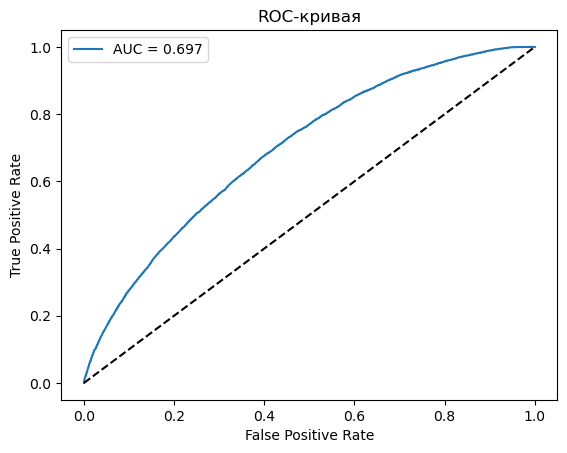

In [99]:
y_proba = best_model.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_proba)

plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.3f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривая')
plt.legend()
plt.show()  

***Лучшая модель RandomForest даёт ROC-AUC на тесте 0.6970, устойчива к дисбалансу классов. Модель значительно превосходит бейслайн.***


In [100]:
# важность признаков
importance_df = pd.DataFrame({
    'feature': X.columns,
    'importance': best_model.feature_importances_  
}).sort_values('importance', ascending=False)

# в проценты
importance_df['importance'] = (importance_df['importance'] * 100).round(2)

print("Важность признаков:")
print(importance_df.head(10).to_string(index=False))

Важность признаков:
      feature  importance
 utm_campaign       21.60
   utm_source       12.85
   utm_medium       11.86
utm_adcontent       11.37
 visit_number       10.16
screen_height        5.96
 device_brand        5.27
 screen_width        5.23
   visit_hour        4.68
     geo_city        4.48


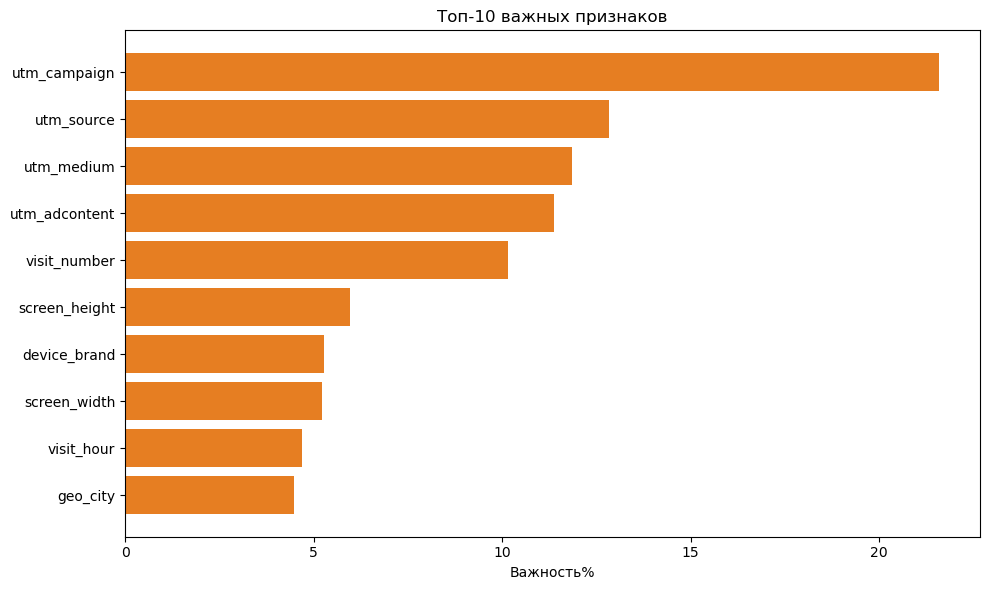

In [107]:
plt.figure(figsize=(10, 6))
plt.barh(top_features['feature'], top_features['importance'], color='#E67E22')
plt.xlabel('Важность%')
plt.title('Топ-10 важных признаков')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show() 

***Главный фактор конверсии - рекламная кампания.***
***utm_campaign, utm_source, utm_medium, utm_adcontent - рекламные параметры самые важные, в сумме образуют почти 60% влияния. Активность пользователя тоже очень важна***

In [106]:
# проверка на переобучение
y_pred_train = best_model.predict_proba(X_train)[:, 1]
train_auc = roc_auc_score(y_train, y_pred_train)

print(f'Train ROC-AUC: {train_auc:.4f}')
print(f'Test ROC-AUC: {roc_auc:.4f}')        
print(f'Разница: {train_auc - roc_auc:.4f}')

Train ROC-AUC: 0.7188
Test ROC-AUC: 0.6970
Разница: 0.0218


***Train и Test близки, переобучения модели нет.***

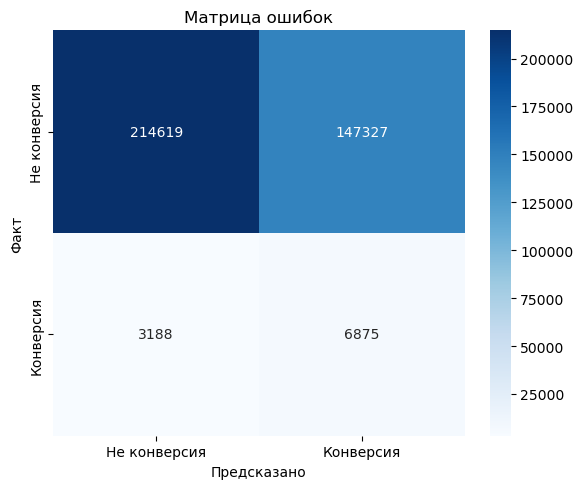

In [108]:
#матрица ошибок
y_pred_class = best_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred_class)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Не конверсия', 'Конверсия'],
            yticklabels=['Не конверсия', 'Конверсия'])
plt.xlabel('Предсказано')
plt.ylabel('Факт')
plt.title('Матрица ошибок')
plt.tight_layout()
plt.show()  

In [109]:
# Обучение финальной модели на всех данных
final_model = RandomForestClassifier(
    **grid_search.best_params_,  
    class_weight='balanced',
    random_state=42,
    n_jobs=10
)

final_model.fit(X_encoded, model_ready['target'])

Модель обучена на 1860042 строках


## Сохранение пайплайна ##

In [115]:
#  данные до кодирования 
X_raw = model_df.drop(columns=['target'])
y = model_df['target']

# списки колонок
categorical_cols = X_raw.select_dtypes(include=['object', 'category']).columns.tolist()
numeric_cols = X_raw.select_dtypes(include=['int64', 'float64']).columns.tolist()

preprocessor = ColumnTransformer([
    ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), categorical_cols),
    ('num', RobustScaler(), numeric_cols)
])

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', final_model)
])

pipeline.fit(X_raw, y)

# Сохраняем файл
joblib.dump(pipeline, 'pipeline.pkl') 

['pipeline.pkl']